# Experiment-7: Text Classification using Deep Learning Models


## Implement sentiment analysis using Logistic regression,  LSTM, and Vanilla Transformer models and BERT pretrained model on IMDB Movie Reviews Dataset and perform comparative analysis among all the models.

(Evaluate using F1, Precision, Recall, and analyse with Confusion Matrix)


In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/IMDB_Dataset.csv')

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Dataset Shape: (50000, 2)

Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
import re
from sklearn.model_selection import train_test_split

df = df.dropna(subset=['review', 'sentiment'])

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['review'] = df['review'].apply(clean_text)

df['sentiment'] = df['sentiment'].str.lower().map({
    'positive': 1,
    'negative': 0
})

df = df.dropna(subset=['sentiment'])

X = df['review'].values
y = df['sentiment'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 40000
Testing Samples: 10000


In [5]:
# Logistic Regression

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, stop_words='english')),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [6]:
# LSTM Model

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_len, padding='post', truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_len, padding='post', truncating='post'
)

print("Tokenization Completed!")

Tokenization Completed!


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

lstm_model = Sequential([
    Embedding(max_words, 128, mask_zero=True),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

lstm_model.fit(
    X_train_pad, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1
)

lstm_pred = (lstm_model.predict(X_test_pad) > 0.5).astype(int).flatten()

print("LSTM Training Completed!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.7935 - loss: 0.4448 - val_accuracy: 0.8565 - val_loss: 0.3539
Epoch 2/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9002 - loss: 0.2603 - val_accuracy: 0.8760 - val_loss: 0.3445
Epoch 3/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9364 - loss: 0.1737 - val_accuracy: 0.8640 - val_loss: 0.3403
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
LSTM Training Completed!


In [8]:
# Vanilla Transformer Model

from tensorflow.keras.layers import (
    Input, Embedding, Dense, Dropout,
    LayerNormalization, MultiHeadAttention,
    GlobalAveragePooling1D, Add
)
from tensorflow.keras.models import Model

inputs = Input(shape=(max_len,))

embedding = Embedding(
    max_words, 128, mask_zero=True
)(inputs)

positions = tf.range(start=0, limit=max_len, delta=1)
position_embedding = Embedding(max_len, 128)(positions)

x = embedding + position_embedding

attention = MultiHeadAttention(
    num_heads=4,
    key_dim=32
)(x, x)

x = Add()([x, attention])
x = LayerNormalization()(x)

ffn = Dense(256, activation='relu')(x)
ffn = Dense(128)(ffn)

x = Add()([x, ffn])
x = LayerNormalization()(x)

x = GlobalAveragePooling1D()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(1, activation='sigmoid')(x)

transformer_model = Model(inputs, outputs)

transformer_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transformer_model.summary()

transformer_model.fit(
    X_train_pad, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1
)

transformer_pred = (
    transformer_model.predict(X_test_pad) > 0.5
).astype(int).flatten()

print("Vanilla Transformer Training Completed!")

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 200, 128)  │  2,560,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 200, 128)  │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 200, 128)  │     66,048 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 200, 128)  │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 200, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 200, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 200, 128)  │     32,896 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 200, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 200, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         65 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,700,801 (10.30 MB)

 Trainable params: 2,700,801 (10.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.8097 - loss: 0.4036 - val_accuracy: 0.8788 - val_loss: 0.2805
Epoch 2/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9137 - loss: 0.2251 - val_accuracy: 0.8727 - val_loss: 0.2972
Epoch 3/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9426 - loss: 0.1619 - val_accuracy: 0.8673 - val_loss: 0.3853
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Vanilla Transformer Training Completed!


In [9]:
# BERT Pretrained Model

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("Using Device:", device)

bert_name = 'bert-base-uncased'

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    bert_name,
    num_labels=2
).to(device)

print("BERT Model Loaded Successfully!")

Using Device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully!


In [10]:
class IMDBDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = bert_tokenizer(
            self.texts[idx],
            max_length=128,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = IMDBDataset(X_train, y_train)
test_dataset = IMDBDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=16
)

print("BERT Dataset Prepared!")

BERT Dataset Prepared!


In [11]:
optimizer = AdamW(bert_model.parameters(), lr=2e-5)

epochs = 2

for epoch in range(epochs):
    bert_model.train()
    total_loss = 0

    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {total_loss/len(train_loader):.4f}"
    )

print("BERT Fine-tuning Completed!")

Epoch 1/2, Loss: 0.3009
Epoch 2/2, Loss: 0.1764
BERT Fine-tuning Completed!


In [12]:
bert_model.eval()

bert_pred = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        bert_pred.extend(predictions.cpu().numpy())

bert_pred = np.array(bert_pred)

print("BERT Predictions Completed!")

BERT Predictions Completed!


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    'Logistic Regression': lr_pred,
    'LSTM': lstm_pred,
    'Vanilla Transformer': transformer_pred,
    'BERT': bert_pred
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\n", name)
    print(classification_report(
        y_test,
        predictions,
        target_names=['Negative', 'Positive']
    ))

results_df = pd.DataFrame(results)

print("\nComparative Analysis:")
print(results_df.round(4).to_string(index=False))


 Logistic Regression
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89      5000
    Positive       0.89      0.90      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.89     10000
weighted avg       0.90      0.90      0.89     10000


 LSTM
              precision    recall  f1-score   support

    Negative       0.87      0.87      0.87      5000
    Positive       0.87      0.87      0.87      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000


 Vanilla Transformer
              precision    recall  f1-score   support

    Negative       0.84      0.91      0.87      5000
    Positive       0.90      0.83      0.86      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87

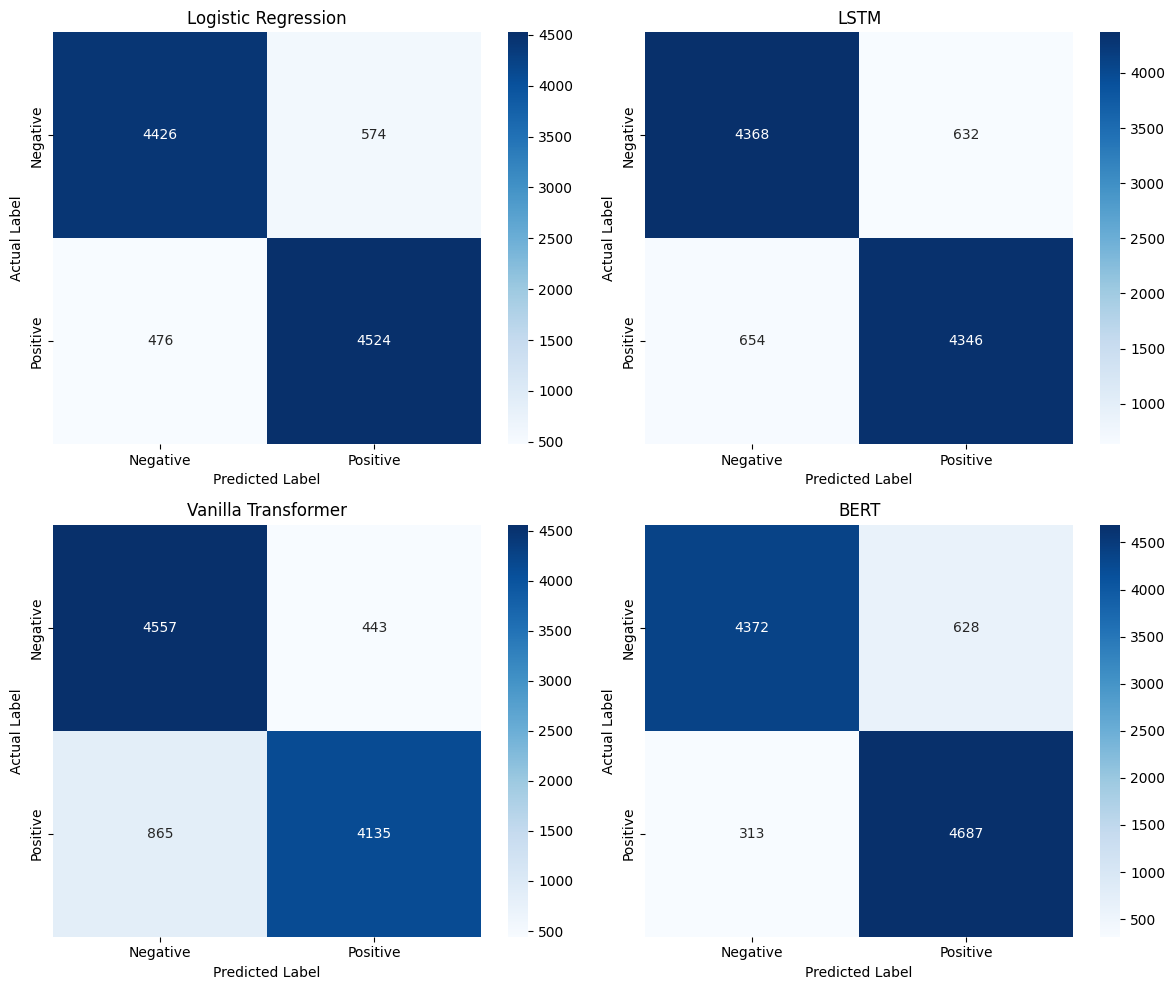

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(axes.flatten(), models.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

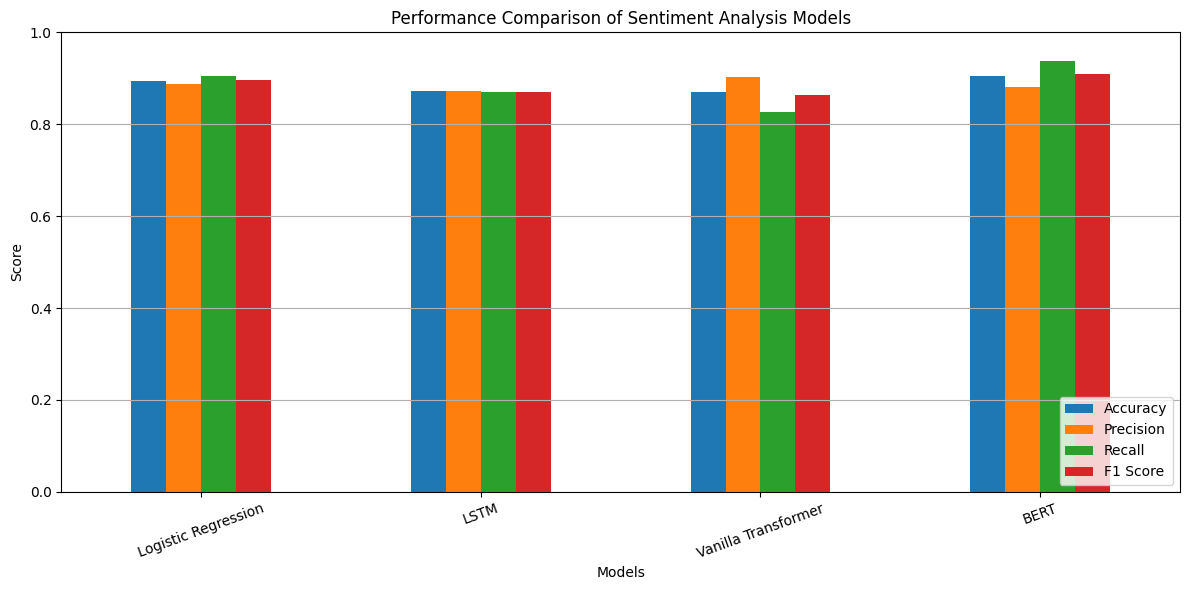

In [15]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(12, 6))

plt.title('Performance Comparison of Sentiment Analysis Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [16]:
best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("Best Performing Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))

Best Performing Model: BERT
Accuracy: 0.9059
Precision: 0.8818
Recall: 0.9374
F1 Score: 0.9088
